In [1]:

from pathlib import Path

PART3_DIR = Path(r"C:\Users\HP\part3_output")

print("PART 3 OUTPUT FILES")
print("-" * 40)

for item in sorted(PART3_DIR.iterdir()):
    print(item.name)
    
    if item.is_dir():
        for subitem in list(item.iterdir())[:5]:
            print("   ", subitem.name)


PART 3 OUTPUT FILES
----------------------------------------
country_performance
    .part-00000-07dc5c63-fc84-498c-8d83-b5151718fac2-c000.csv.crc
    ._SUCCESS.crc
    part-00000-07dc5c63-fc84-498c-8d83-b5151718fac2-c000.csv
    _SUCCESS
customer_clv_engagement
    .part-00000-3be70bf2-e533-4617-900c-f9ce46526cef-c000.csv.crc
    ._SUCCESS.crc
    part-00000-3be70bf2-e533-4617-900c-f9ce46526cef-c000.csv
    _SUCCESS
customer_segment_summary
    .part-00000-3766a584-943a-4a16-bd9a-b328a0b8f6db-c000.csv.crc
    ._SUCCESS.crc
    part-00000-3766a584-943a-4a16-bd9a-b328a0b8f6db-c000.csv
    _SUCCESS
engagement_vs_purchases
    .part-00000-acb043b9-4108-458f-a123-2c23e2338d11-c000.csv.crc
    ._SUCCESS.crc
    part-00000-acb043b9-4108-458f-a123-2c23e2338d11-c000.csv
    _SUCCESS
integrated_customer_analytics.parquet
    .part-00000-a2540ca0-a968-4349-93f7-24a07c87f41f-c000.snappy.parquet.crc
    .part-00001-a2540ca0-a968-4349-93f7-24a07c87f41f-c000.snappy.parquet.crc
    .part-00002-a2540c

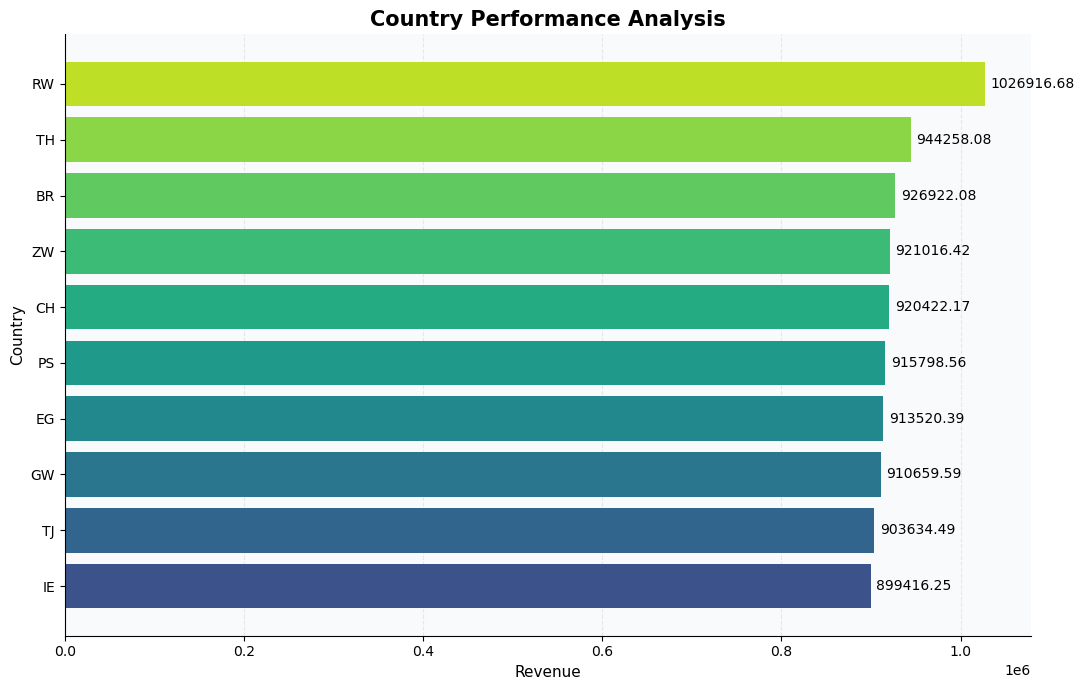

Saved chart and data: 01_country_performance.png


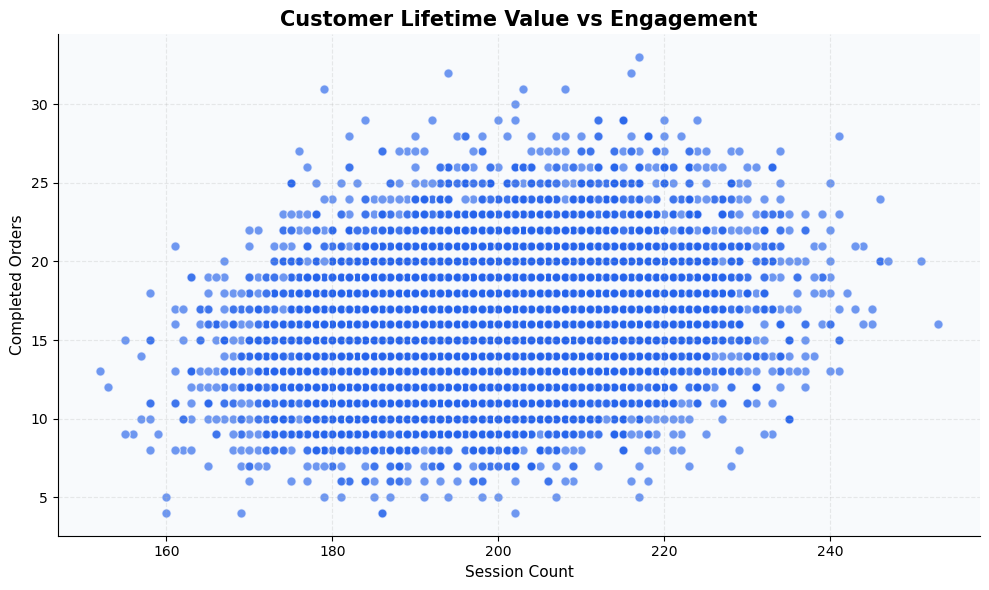

Saved chart and data: 02_customer_clv_engagement.png


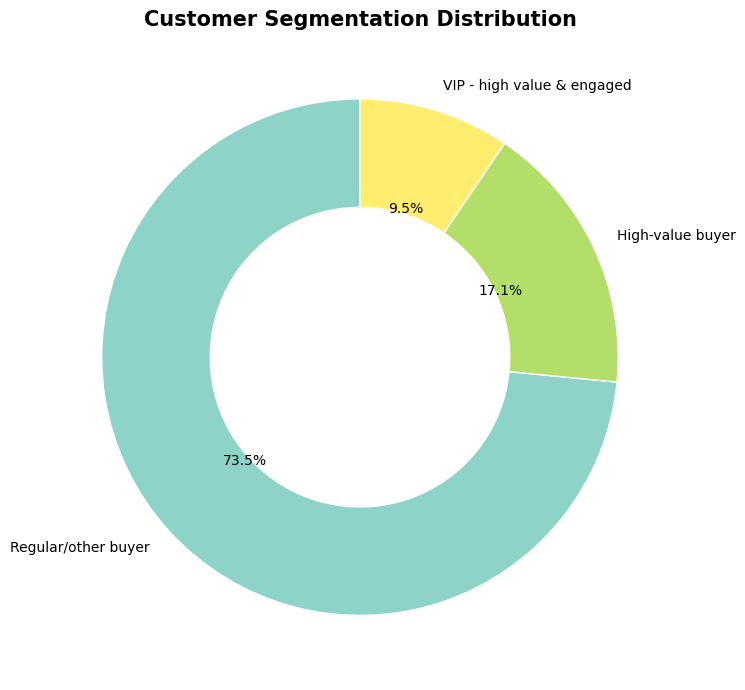

Saved chart and data: 03_customer_segmentation.png


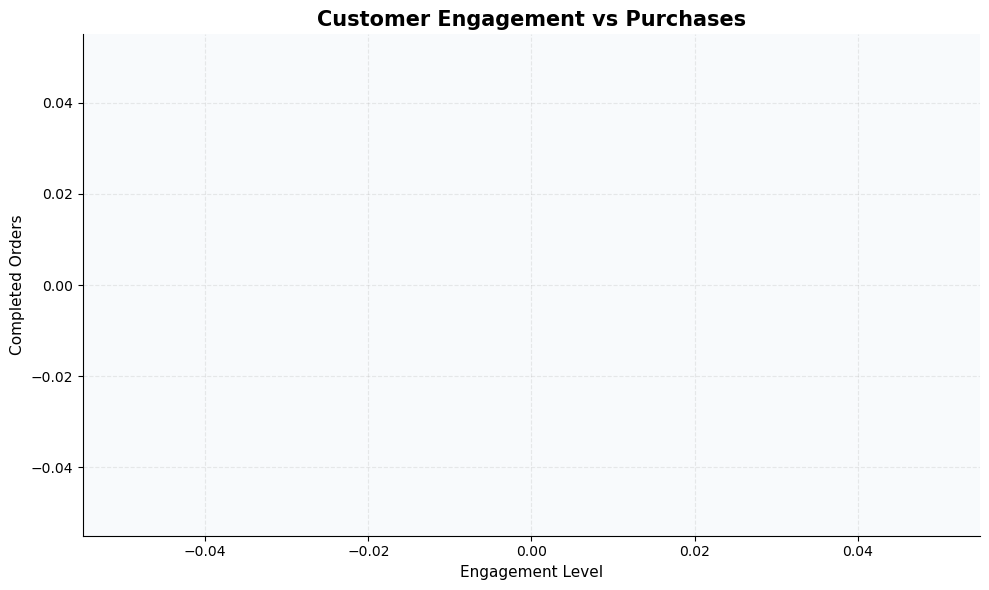

Saved chart and data: 04_engagement_vs_purchases.png


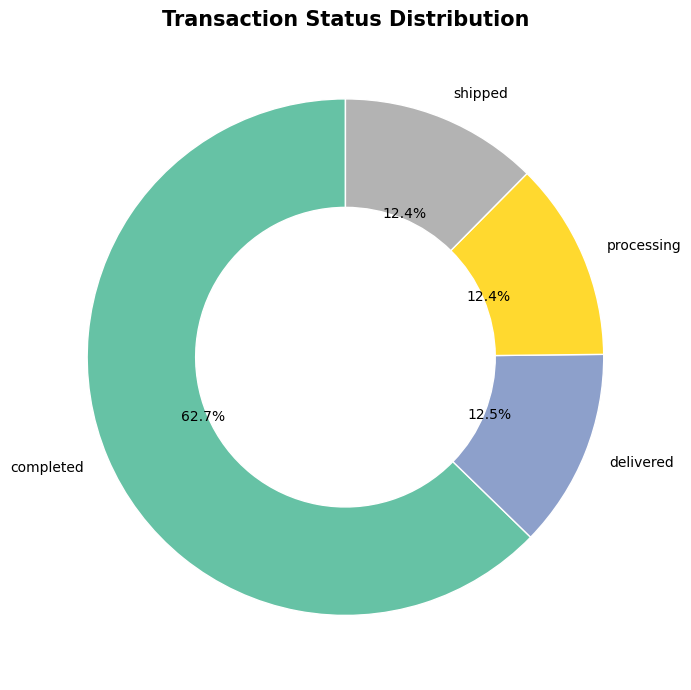

Saved chart and data: 05_transaction_status.png

PART 4 COMPLETED
Charts and corresponding CSV data saved to: C:\Users\HP\part4_visualizations


In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

BASE = Path(r"C:\Users\HP\part3_output")
OUT = Path(r"C:\Users\HP\part4_visualizations")
OUT.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#F8FAFC",
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "font.size": 10
})

def load_data(folder):
    f = next((BASE / folder).glob("part-*.csv"))
    return pd.read_csv(f)

def find_col(df, keywords):
    return next(
        (c for c in df.columns
         if any(k in c.lower() for k in keywords)),
        None
    )

def save_plot(name, df, filename):
    plt.tight_layout()
    plt.savefig(OUT / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    df.to_csv(OUT / (filename.replace(".png", ".csv")), index=False)
    print("Saved chart and data:", filename)


# 1. COUNTRY PERFORMANCE
df = load_data("country_performance")
country = find_col(df, ["country"])
metric = find_col(df, [
    "total_revenue", "revenue", "total_customers",
    "customer_count", "total_users", "total_sessions",
    "total_purchases", "purchases"
])

if metric is None:
    metric = df.select_dtypes(include="number").columns[0]

df[metric] = pd.to_numeric(df[metric], errors="coerce")
d = df.dropna(subset=[country, metric]).nlargest(10, metric)
d = d.sort_values(metric)

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(d[country].astype(str), d[metric],
               color=plt.cm.viridis(np.linspace(.25, .9, len(d))))
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_title("Country Performance Analysis")
ax.set_xlabel(metric.replace("_", " ").title())
ax.set_ylabel("Country")
ax.grid(axis="x", linestyle="--", alpha=.25)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
save_plot("01_country_performance", d, "01_country_performance.png")


# 2. CUSTOMER CLV AND ENGAGEMENT
df = load_data("customer_clv_engagement")
clv = find_col(df, ["clv", "lifetime_value", "customer_value"])
eng = find_col(df, ["engagement_score", "total_sessions",
                    "session_count", "engagement"])

nums = df.select_dtypes(include="number").columns.tolist()

if clv is None:
    clv = nums[0]
if eng is None:
    eng = next(c for c in nums if c != clv)

d = df[[eng, clv]].apply(pd.to_numeric, errors="coerce").dropna()

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(d[eng], d[clv], color="#2563EB",
           alpha=.65, s=45, edgecolors="white")
ax.set_title("Customer Lifetime Value vs Engagement")
ax.set_xlabel(eng.replace("_", " ").title())
ax.set_ylabel(clv.replace("_", " ").title())
ax.grid(linestyle="--", alpha=.25)
ax.spines[["top", "right"]].set_visible(False)
save_plot("02_customer_clv_engagement", d,
          "02_customer_clv_engagement.png")


# 3. CUSTOMER SEGMENTATION
df = load_data("customer_segment_summary")
segment = find_col(df, ["segment", "customer_type", "category", "group"])
count = find_col(df, ["customer_count", "total_customers",
                      "count", "customers", "total_users"])

if count is None:
    count = df.select_dtypes(include="number").columns[0]
if segment is None:
    segment = next(c for c in df.columns if c != count)

d = df[[segment, count]].copy()
d[count] = pd.to_numeric(d[count], errors="coerce")
d = d.dropna()

fig, ax = plt.subplots(figsize=(9, 7))
wedges, texts, labels = ax.pie(
    d[count], labels=d[segment].astype(str),
    autopct="%1.1f%%", startangle=90,
    colors=plt.cm.Set3(np.linspace(0, 1, len(d))),
    wedgeprops={"width": .42, "edgecolor": "white"}
)
ax.set_title("Customer Segmentation Distribution")
save_plot("03_customer_segmentation", d,
          "03_customer_segmentation.png")


# 4. ENGAGEMENT VS PURCHASES
df = load_data("engagement_vs_purchases")
x = find_col(df, ["engagement_score", "total_sessions",
                  "session_count", "engagement", "views"])
y = find_col(df, ["total_purchases", "purchase_count",
                  "purchases", "orders", "transactions"])

nums = df.select_dtypes(include="number").columns.tolist()
if x is None:
    x = nums[0]
if y is None:
    y = next(c for c in nums if c != x)

d = df[[x, y]].apply(pd.to_numeric, errors="coerce").dropna()

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(d[x], d[y], color="#0D9488",
           alpha=.65, s=45, edgecolors="white")
ax.set_title("Customer Engagement vs Purchases")
ax.set_xlabel(x.replace("_", " ").title())
ax.set_ylabel(y.replace("_", " ").title())
ax.grid(linestyle="--", alpha=.25)
ax.spines[["top", "right"]].set_visible(False)
save_plot("04_engagement_vs_purchases", d,
          "04_engagement_vs_purchases.png")


# 5. TRANSACTION STATUS
df = load_data("transaction_status_summary")
status = find_col(df, ["status"])
count = find_col(df, ["transaction_count", "total_transactions",
                      "count", "total", "transactions"])

if count is None:
    count = df.select_dtypes(include="number").columns[0]
if status is None:
    status = next(c for c in df.columns if c != count)

d = df[[status, count]].copy()
d[count] = pd.to_numeric(d[count], errors="coerce")
d = d.dropna()

fig, ax = plt.subplots(figsize=(9, 7))
ax.pie(
    d[count], labels=d[status].astype(str),
    autopct=lambda p: f"{p:.1f}%",
    startangle=90,
    colors=plt.cm.Set2(np.linspace(0, 1, len(d))),
    wedgeprops={"width": .42, "edgecolor": "white"}
)
ax.set_title("Transaction Status Distribution")
save_plot("05_transaction_status", d,
          "05_transaction_status.png")


print("\nPART 4 COMPLETED")
print("Charts and corresponding CSV data saved to:", OUT)
